## آماده‌سازی محیط و بارگذاری داده‌ها


In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
ZIP_PATH = DATA_DIR / "alzheimer.zip"
EXTRACT_DIR = DATA_DIR / "extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

uds_matches = list(EXTRACT_DIR.rglob("udslong_imputed.csv"))
mri_matches = list(EXTRACT_DIR.rglob("mriscanclean.csv"))

if not (uds_matches and mri_matches):
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {ZIP_PATH}. Put alzheimer.zip inside the data folder "
            "or update ZIP_PATH to the correct location."
        )
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

uds_path = next(EXTRACT_DIR.rglob("udslong_imputed.csv"), None)
mri_path = next(EXTRACT_DIR.rglob("mriscanclean.csv"), None)

if uds_path is None or mri_path is None:
    raise FileNotFoundError("The required UDS and/or MRI CSV file was not found.")

uds = pd.read_csv(uds_path)
mri = pd.read_csv(mri_path)

print("UDS file:", uds_path.name)
print("MRI file:", mri_path.name)
print("UDS shape:", uds.shape)
print("MRI shape:", mri.shape)

UDS file: udslong_imputed.csv
MRI file: mriscanclean.csv
UDS shape: (1237, 180)
MRI shape: (1237, 126)


## ساختار مجموعه‌داده و واحد مشاهده


In [2]:
print("UDS — first five rows")
display(uds.head())

print("MRI — first five rows")
display(mri.head())

print("\nUDS data types")
display(uds.dtypes.value_counts().rename("Number of columns").to_frame())

print("\nMRI data types")
display(mri.dtypes.value_counts().rename("Number of columns").to_frame())

UDS — first five rows


,NACCID,SEX,HISPANIC,HISPOR,RACE,PRIMLANG,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,NACCNIHR,NACCAGE,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMS,NACCFM,NACCFMS,NACCOM,NACCOMS,NACCFADM,NACCFFTD,ANYMEDS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,CVHATT,CVAFIB,CVANGIO,CVBYPASS,CVPACDEF,CVCHF,CVOTHR,CBSTROKE,CBTIA,SEIZURES,NACCTBI,TBI,TBIBRIEF,TBIEXTEN,TBIWOLOS,DIABETES,DIABTYPE,HYPERTEN,HYPERCHO,B12DEF,...,NITESEV,APP,APPSEV,NOGDS,SATIS,DROPACT,EMPTY,BORED,SPIRITS,AFRAID,HAPPY,HELPLESS,STAYHOME,MEMPROB,WONDRFUL,WRTHLESS,ENERGY,HOPELESS,BETTER,NACCGDS,BILLS,TAXES,SHOPPING,GAMES,STOVE,MEALPREP,EVENTS,PAYATTN,REMDATES,TRAVEL,DECSUB,ANIMALS,VEG,TRAILA,TRAILARR,TRAILALI,TRAILB,TRAILBRR,TRAILBLI,MOCATOTS,NACCAPOE,NACCUDSD,MEMORY,ORIENT,JUDGMENT,COMMUN,HOMEHOBB,PERSCARE,CDRSUM,CDRGLOB
0,NACC359836,1.00,0.00,88.00,1.00,1.00,18.00,1.00,2.00,1.00,1.00,1.00,74.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,0.80,0.00,1.00,10.00,3.00,30.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,1.00,1.00,9.00,...,2.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,1.00,0.00,26.00,11.00,25.00,0.00,24.00,70.00,0.00,24.00,25.00,4.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,NACC990210,2.00,0.00,88.00,1.00,1.00,16.00,1.00,2.00,1.00,1.00,1.00,71.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,0.00,0.00,...,8.00,0.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,23.00,13.00,26.00,0.00,24.00,74.00,0.00,24.00,24.00,1.00,1.00,0.50,0.00,0.00,0.00,0.00,0.00,0.50,0.50
2,NACC074744,1.00,0.00,88.00,1.00,1.00,20.00,1.00,2.00,1.00,1.00,1.00,78.00,1.00,1.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,1.00,8.00,3.00,29.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.00,0.00,0.00,0.00,...,8.00,0.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,2.00,2.00,0.00,0.00,0.00,1.00,2.00,2.00,1.00,0.00,15.00,8.00,36.20,0.20,24.00,104.80,0.60,24.00,24.00,9.00,3.00,1.00,0.50,0.50,0.50,0.50,0.00,3.00,0.50
3,NACC083525,1.00,0.00,88.00,1.00,1.00,16.00,1.00,2.00,1.00,1.00,1.00,66.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,0.00,0.00,...,8.00,0.00,8.00,0.00,1.00,0.00,1.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,24.00,23.00,28.00,0.00,24.00,59.00,1.00,24.00,26.00,9.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,NACC092141,2.00,0.00,88.00,1.00,1.00,14.00,1.00,2.00,1.00,1.00,1.00,65.00,1.00,1.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,3.00,1.00,1.00,0.00,...,8.00,0.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,18.00,14.00,33.00,0.00,24.00,45.00,0.00,24.00,21.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


MRI — first five rows


,NACCID,LH_CAUDALANTERIORCINGULATE_GVOL,RH_CAUDALANTERIORCINGULATE_GVOL,LH_CAUDALANTERIORCINGULATE_AVGTH,RH_CAUDALANTERIORCINGULATE_AVGTH,LH_CAUDALMIDDLEFRONTAL_GVOL,RH_CAUDALMIDDLEFRONTAL_GVOL,LH_CAUDALMIDDLEFRONTAL_AVGTH,RH_CAUDALMIDDLEFRONTAL_AVGTH,LH_CUNEUS_GVOL,RH_CUNEUS_GVOL,LH_CUNEUS_AVGTH,RH_CUNEUS_AVGTH,LH_ENTORHINAL_GVOL,RH_ENTORHINAL_GVOL,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_AVGTH,LH_FUSIFORM_GVOL,RH_FUSIFORM_GVOL,LH_FUSIFORM_AVGTH,RH_FUSIFORM_AVGTH,LH_INFERIORPARIETAL_GVOL,RH_INFERIORPARIETAL_GVOL,LH_INFERIORPARIETAL_AVGTH,RH_INFERIORPARIETAL_AVGTH,LH_INFERIORTEMPORAL_GVOL,RH_INFERIORTEMPORAL_GVOL,LH_INFERIORTEMPORAL_AVGTH,RH_INFERIORTEMPORAL_AVGTH,LH_ISTHMUSCINGULATE_GVOL,RH_ISTHMUSCINGULATE_GVOL,LH_ISTHMUSCINGULATE_AVGTH,RH_ISTHMUSCINGULATE_AVGTH,LH_LATERALOCCIPITAL_GVOL,RH_LATERALOCCIPITAL_GVOL,LH_LATERALOCCIPITAL_AVGTH,RH_LATERALOCCIPITAL_AVGTH,LH_LATERALORBITOFRONTAL_GVOL,RH_LATERALORBITOFRONTAL_GVOL,LH_LATERALORBITOFRONTAL_AVGTH,RH_LATERALORBITOFRONTAL_AVGTH,LH_LINGUAL_GVOL,RH_LINGUAL_GVOL,LH_LINGUAL_AVGTH,RH_LINGUAL_AVGTH,LH_MEDIALORBITOFRONTAL_GVOL,RH_MEDIALORBITOFRONTAL_GVOL,LH_MEDIALORBITOFRONTAL_AVGTH,RH_MEDIALORBITOFRONTAL_AVGTH,LH_MIDDLETEMPORAL_GVOL,...,RH_PERICALCARINE_AVGTH,LH_POSTCENTRAL_GVOL,RH_POSTCENTRAL_GVOL,LH_POSTCENTRAL_AVGTH,RH_POSTCENTRAL_AVGTH,LH_POSTERIORCINGULATE_GVOL,RH_POSTERIORCINGULATE_GVOL,LH_POSTERIORCINGULATE_AVGTH,RH_POSTERIORCINGULATE_AVGTH,LH_PRECENTRAL_GVOL,RH_PRECENTRAL_GVOL,LH_PRECENTRAL_AVGTH,RH_PRECENTRAL_AVGTH,LH_PRECUNEUS_GVOL,RH_PRECUNEUS_GVOL,LH_PRECUNEUS_AVGTH,RH_PRECUNEUS_AVGTH,LH_ROSTRALANTERIORCINGULATE_GVOL,RH_ROSTRALANTERIORCINGULATE_GVOL,LH_ROSTRALANTERIORCINGULATE_AVGTH,RH_ROSTRALANTERIORCINGULATE_AVGTH,LH_ROSTRALMIDDLEFRONTAL_GVOL,RH_ROSTRALMIDDLEFRONTAL_GVOL,LH_ROSTRALMIDDLEFRONTAL_AVGTH,RH_ROSTRALMIDDLEFRONTAL_AVGTH,LH_SUPERIORFRONTAL_GVOL,RH_SUPERIORFRONTAL_GVOL,LH_SUPERIORFRONTAL_AVGTH,RH_SUPERIORFRONTAL_AVGTH,LH_SUPERIORPARIETAL_GVOL,RH_SUPERIORPARIETAL_GVOL,LH_SUPERIORPARIETAL_AVGTH,RH_SUPERIORPARIETAL_AVGTH,LH_SUPERIORTEMPORAL_GVOL,RH_SUPERIORTEMPORAL_GVOL,LH_SUPERIORTEMPORAL_AVGTH,RH_SUPERIORTEMPORAL_AVGTH,LH_SUPRAMARGINAL_GVOL,RH_SUPRAMARGINAL_GVOL,LH_SUPRAMARGINAL_AVGTH,RH_SUPRAMARGINAL_AVGTH,LH_TRANSVERSETEMPORAL_GVOL,RH_TRANSVERSETEMPORAL_GVOL,LH_TRANSVERSETEMPORAL_AVGTH,RH_TRANSVERSETEMPORAL_AVGTH,LH_INSULA_GVOL,RH_INSULA_GVOL,LH_INSULA_AVGTH,RH_INSULA_AVGTH,NACCUDSD
0,NACC359836,3462,2257,2.33,2.28,6767,5857,2.27,2.30,5726,6273,1.89,2.02,1589,1980,3.22,3.27,8573,8600,2.61,2.76,9076,12262,2.22,2.27,10759,12439,2.65,2.77,2602,2255,2.12,2.07,12277,13939,2.04,2.19,7709,8219,2.49,2.85,7427,8165,2.00,2.14,4109,3933,2.35,2.43,10945,...,1.83,12441,10971,2.06,2.05,3764,3689,2.33,2.31,13365,12287,2.27,2.30,10992,10553,2.19,2.18,3124,2754,2.54,2.66,11164,12716,2.36,2.35,23235,24853,2.41,2.45,11310,11977,2.08,2.08,16384,16295,2.64,2.64,10912,8032,2.32,2.33,1028,786,2.06,2.08,5785,6224,3.04,3.13,1
1,NACC990210,3131,2528,2.55,2.29,6898,6880,2.48,2.42,4512,4394,2.10,2.01,1511,1713,3.07,3.54,8298,6886,2.69,2.61,13248,15095,2.33,2.32,11459,10360,2.68,2.71,2673,2625,2.28,2.11,11274,12394,2.23,2.29,9036,8257,2.41,2.42,6971,7587,2.06,2.05,4238,4418,2.36,2.24,11449,...,1.79,9450,8882,1.99,1.90,3412,3086,2.36,2.41,11996,11172,2.33,2.25,10192,10004,2.36,2.35,2893,3136,2.57,2.50,9852,8934,2.33,2.33,24131,25894,2.50,2.51,12636,12783,2.21,2.10,13034,13131,2.51,2.62,9400,9347,2.36,2.38,1430,783,2.19,2.48,6075,6200,3.00,2.85,1
2,NACC074744,2463,1618,2.06,1.94,7176,5770,2.25,2.27,4240,4688,1.85,1.91,642,1928,1.45,2.77,9766,7501,2.37,2.43,10702,14880,2.10,2.17,9421,9884,2.26,2.49,2826,2426,2.21,1.98,12036,12835,1.91,2.11,8531,6590,2.37,2.75,7099,8340,1.80,1.94,5155,5276,2.57,2.65,11310,...,1.93,12874,14910,1.97,1.97,2807,3316,2.19,2.33,12255,13860,2.05,2.11,10460,11069,2.10,1.99,3719,1895,2.42,2.56,12368,11254,2.24,2.56,25838,25969,2.37,2.49,11767,11103,1.94,1.98,13189,11519,2.24,2.31,9832,9569,2.24,2.16,1299,1036,2.20,2.20,5912,6344,2.65,2.85,3
3,NACC083525,2980,2302,2.40,2.23


UDS data types


,Number of columns
float64,179
str,1



MRI data types


,Number of columns
int64,63
float64,62
str,1


### شناسه شرکت‌کنندگان و رکوردهای تکراری

In [3]:
for name, df in [("UDS", uds), ("MRI", mri)]:
    if "NACCID" not in df.columns:
        raise KeyError(f"{name} does not contain NACCID.")

    print(f"--- {name} ---")
    print("Rows:", len(df))
    print("Unique participant IDs:", df["NACCID"].nunique(dropna=True))
    print("Missing participant IDs:", df["NACCID"].isna().sum())
    print("Duplicated participant IDs:", df["NACCID"].duplicated().sum())
    print("Participants with more than one row:",
          int((df["NACCID"].value_counts() > 1).sum()))

--- UDS ---
Rows: 1237
Unique participant IDs: 1237
Missing participant IDs: 0
Duplicated participant IDs: 0
Participants with more than one row: 0
--- MRI ---
Rows: 1237
Unique participant IDs: 1237
Missing participant IDs: 0
Duplicated participant IDs: 0
Participants with more than one row: 0


### ساختار ویزیت و زمان
برای یافتن شیوه ی ای که دیتاهای زیرمجوعه جمع اوری شدن به جز یکتایی شناسه ها سراغ بررسی اینکه مراجعه ی چندمه یا اینکه دیتا به صورت تاریخی چجوری جدا شده و اینها میرویم تا در دیتا بفهمیم تقسیم بندی ایا تصادفی بوده است یا براساس معیار مشخصی است.

In [4]:
visit_keywords = [
    "VISIT", "AVST", "DATE", "YEAR", "MONTH",
    "EXAM", "SCAN",
]

for name, df in [("UDS", uds), ("MRI", mri)]:
    matches = [
        col for col in df.columns
        if any(keyword in col.upper() for keyword in visit_keywords)
    ]
    print(f"{name} possible visit/time fields:", matches)

for col in ["NORMEXAM", "REMDATES"]:
    if col in uds.columns:
        print(f"\n{col} — data type: {uds[col].dtype}")
        display(uds[col].value_counts(dropna=False).sort_index().to_frame("Frequency"))

UDS possible visit/time fields: ['NORMEXAM', 'REMDATES']
MRI possible visit/time fields: []

NORMEXAM — data type: float64


,Frequency
NORMEXAM,
0.00,803
0.20,19
0.40,86
0.60,17
0.80,30
1.00,87
1.20,7
1.40,2
1.60,1



REMDATES — data type: float64


,Frequency
REMDATES,
0.00,958
0.20,11
0.40,5
0.60,3
1.00,146
1.40,1
1.80,1
2.00,76
3.00,32


### واحد مشاهده و استقلال مشاهدات

## ادغام داده‌های UDS و MRI


In [5]:

uds_ids = set(uds["NACCID"].dropna().astype("string").str.strip())
mri_ids = set(mri["NACCID"].dropna().astype("string").str.strip())

common_ids = uds_ids & mri_ids
uds_only_ids = uds_ids - mri_ids
mri_only_ids = mri_ids - uds_ids

id_audit = pd.DataFrame({
    "Dataset": ["UDS", "MRI", "Common"],
    "Unique_IDs": [len(uds_ids), len(mri_ids), len(common_ids)]
})

display(id_audit)
print("UDS-only IDs:", len(uds_only_ids))
print("MRI-only IDs:", len(mri_only_ids))
print("ID sets identical:", uds_ids == mri_ids)

# One-to-one merge; validation raises an error if IDs are duplicated.
combined = pd.merge(
    uds,
    mri,
    on="NACCID",
    how="inner",
    suffixes=("_UDS", "_MRI"),
    validate="one_to_one"
)

print("UDS shape:", uds.shape)
print("MRI shape:", mri.shape)
print("Merged shape:", combined.shape)
print("Unique IDs after merge:", combined["NACCID"].nunique())
print("Duplicated IDs after merge:", combined["NACCID"].duplicated().sum())

,Dataset,Unique_IDs
0,UDS,1237
1,MRI,1237
2,Common,1237


UDS-only IDs: 0
MRI-only IDs: 0
ID sets identical: True
UDS shape: (1237, 180)
MRI shape: (1237, 126)
Merged shape: (1237, 305)
Unique IDs after merge: 1237
Duplicated IDs after merge: 0


بررسی کلی داده های مرج شده

In [6]:
sns.set_theme(style="whitegrid")
print("Dataset Shape:", combined.shape)
print("Number of Rows:", combined.shape[0])
print("Number of Columns:", combined.shape[1])
print("Total Cells:", combined.size)

print("Duplicate Rows:", combined.duplicated().sum())

print("Unique Participants:", combined["NACCID"].nunique())

Dataset Shape: (1237, 305)
Number of Rows: 1237
Number of Columns: 305
Total Cells: 377285
Duplicate Rows: 0
Unique Participants: 1237


In [7]:
display(combined.head())

,NACCID,SEX,HISPANIC,HISPOR,RACE,PRIMLANG,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,NACCNIHR,NACCAGE,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMS,NACCFM,NACCFMS,NACCOM,NACCOMS,NACCFADM,NACCFFTD,ANYMEDS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,CVHATT,CVAFIB,CVANGIO,CVBYPASS,CVPACDEF,CVCHF,CVOTHR,CBSTROKE,CBTIA,SEIZURES,NACCTBI,TBI,TBIBRIEF,TBIEXTEN,TBIWOLOS,DIABETES,DIABTYPE,HYPERTEN,HYPERCHO,B12DEF,...,RH_PERICALCARINE_AVGTH,LH_POSTCENTRAL_GVOL,RH_POSTCENTRAL_GVOL,LH_POSTCENTRAL_AVGTH,RH_POSTCENTRAL_AVGTH,LH_POSTERIORCINGULATE_GVOL,RH_POSTERIORCINGULATE_GVOL,LH_POSTERIORCINGULATE_AVGTH,RH_POSTERIORCINGULATE_AVGTH,LH_PRECENTRAL_GVOL,RH_PRECENTRAL_GVOL,LH_PRECENTRAL_AVGTH,RH_PRECENTRAL_AVGTH,LH_PRECUNEUS_GVOL,RH_PRECUNEUS_GVOL,LH_PRECUNEUS_AVGTH,RH_PRECUNEUS_AVGTH,LH_ROSTRALANTERIORCINGULATE_GVOL,RH_ROSTRALANTERIORCINGULATE_GVOL,LH_ROSTRALANTERIORCINGULATE_AVGTH,RH_ROSTRALANTERIORCINGULATE_AVGTH,LH_ROSTRALMIDDLEFRONTAL_GVOL,RH_ROSTRALMIDDLEFRONTAL_GVOL,LH_ROSTRALMIDDLEFRONTAL_AVGTH,RH_ROSTRALMIDDLEFRONTAL_AVGTH,LH_SUPERIORFRONTAL_GVOL,RH_SUPERIORFRONTAL_GVOL,LH_SUPERIORFRONTAL_AVGTH,RH_SUPERIORFRONTAL_AVGTH,LH_SUPERIORPARIETAL_GVOL,RH_SUPERIORPARIETAL_GVOL,LH_SUPERIORPARIETAL_AVGTH,RH_SUPERIORPARIETAL_AVGTH,LH_SUPERIORTEMPORAL_GVOL,RH_SUPERIORTEMPORAL_GVOL,LH_SUPERIORTEMPORAL_AVGTH,RH_SUPERIORTEMPORAL_AVGTH,LH_SUPRAMARGINAL_GVOL,RH_SUPRAMARGINAL_GVOL,LH_SUPRAMARGINAL_AVGTH,RH_SUPRAMARGINAL_AVGTH,LH_TRANSVERSETEMPORAL_GVOL,RH_TRANSVERSETEMPORAL_GVOL,LH_TRANSVERSETEMPORAL_AVGTH,RH_TRANSVERSETEMPORAL_AVGTH,LH_INSULA_GVOL,RH_INSULA_GVOL,LH_INSULA_AVGTH,RH_INSULA_AVGTH,NACCUDSD_MRI
0,NACC359836,1.00,0.00,88.00,1.00,1.00,18.00,1.00,2.00,1.00,1.00,1.00,74.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,0.80,0.00,1.00,10.00,3.00,30.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,1.00,1.00,9.00,...,1.83,12441,10971,2.06,2.05,3764,3689,2.33,2.31,13365,12287,2.27,2.30,10992,10553,2.19,2.18,3124,2754,2.54,2.66,11164,12716,2.36,2.35,23235,24853,2.41,2.45,11310,11977,2.08,2.08,16384,16295,2.64,2.64,10912,8032,2.32,2.33,1028,786,2.06,2.08,5785,6224,3.04,3.13,1
1,NACC990210,2.00,0.00,88.00,1.00,1.00,16.00,1.00,2.00,1.00,1.00,1.00,71.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,0.00,0.00,...,1.79,9450,8882,1.99,1.90,3412,3086,2.36,2.41,11996,11172,2.33,2.25,10192,10004,2.36,2.35,2893,3136,2.57,2.50,9852,8934,2.33,2.33,24131,25894,2.50,2.51,12636,12783,2.21,2.10,13034,13131,2.51,2.62,9400,9347,2.36,2.38,1430,783,2.19,2.48,6075,6200,3.00,2.85,1
2,NACC074744,1.00,0.00,88.00,1.00,1.00,20.00,1.00,2.00,1.00,1.00,1.00,78.00,1.00,1.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,1.00,8.00,3.00,29.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.00,0.00,0.00,0.00,...,1.93,12874,14910,1.97,1.97,2807,3316,2.19,2.33,12255,13860,2.05,2.11,10460,11069,2.10,1.99,3719,1895,2.42,2.56,12368,11254,2.24,2.56,25838,25969,2.37,2.49,11767,11103,1.94,1.98,13189,11519,2.24,2.31,9832,9569,2.24,2.16,1299,1036,2.20,2.20,5912,6344,2.65,2.85,3
3,NACC083525,1.00,0.00,88.00,1.00,1.00,16.00,1.00,2.00,1.00,1.00,1.00,66.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,0.00,0.00,...,2.01,10039,10611,2.17,2.18,3289,3009,2.34,2.18,13779,12681,2.66,2.58,9464,10441,2.52,2.58,3409,2317,2.54,2.75,10077,11255,2.50,2.38,24475,25308,2.60,2.61,9828,9836,2.41,2.32,17053,15969,2.86,2.87,10668,10168,2.57,2.60,1061,846,2.44,2.55,6226,6050,3.12,3.03,1
4,NACC092141,2.00,0.00,88.00,1.00,1.00,14.00,1.00,2.00,1.00,1.00,1.00,65.00,1.00,1.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,3.00,1.00,1.00,0.00,...,1.77,10103,9150,2.21,2.16,3278,2

In [8]:
display(combined.tail())

,NACCID,SEX,HISPANIC,HISPOR,RACE,PRIMLANG,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,NACCNIHR,NACCAGE,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMS,NACCFM,NACCFMS,NACCOM,NACCOMS,NACCFADM,NACCFFTD,ANYMEDS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,CVHATT,CVAFIB,CVANGIO,CVBYPASS,CVPACDEF,CVCHF,CVOTHR,CBSTROKE,CBTIA,SEIZURES,NACCTBI,TBI,TBIBRIEF,TBIEXTEN,TBIWOLOS,DIABETES,DIABTYPE,HYPERTEN,HYPERCHO,B12DEF,...,RH_PERICALCARINE_AVGTH,LH_POSTCENTRAL_GVOL,RH_POSTCENTRAL_GVOL,LH_POSTCENTRAL_AVGTH,RH_POSTCENTRAL_AVGTH,LH_POSTERIORCINGULATE_GVOL,RH_POSTERIORCINGULATE_GVOL,LH_POSTERIORCINGULATE_AVGTH,RH_POSTERIORCINGULATE_AVGTH,LH_PRECENTRAL_GVOL,RH_PRECENTRAL_GVOL,LH_PRECENTRAL_AVGTH,RH_PRECENTRAL_AVGTH,LH_PRECUNEUS_GVOL,RH_PRECUNEUS_GVOL,LH_PRECUNEUS_AVGTH,RH_PRECUNEUS_AVGTH,LH_ROSTRALANTERIORCINGULATE_GVOL,RH_ROSTRALANTERIORCINGULATE_GVOL,LH_ROSTRALANTERIORCINGULATE_AVGTH,RH_ROSTRALANTERIORCINGULATE_AVGTH,LH_ROSTRALMIDDLEFRONTAL_GVOL,RH_ROSTRALMIDDLEFRONTAL_GVOL,LH_ROSTRALMIDDLEFRONTAL_AVGTH,RH_ROSTRALMIDDLEFRONTAL_AVGTH,LH_SUPERIORFRONTAL_GVOL,RH_SUPERIORFRONTAL_GVOL,LH_SUPERIORFRONTAL_AVGTH,RH_SUPERIORFRONTAL_AVGTH,LH_SUPERIORPARIETAL_GVOL,RH_SUPERIORPARIETAL_GVOL,LH_SUPERIORPARIETAL_AVGTH,RH_SUPERIORPARIETAL_AVGTH,LH_SUPERIORTEMPORAL_GVOL,RH_SUPERIORTEMPORAL_GVOL,LH_SUPERIORTEMPORAL_AVGTH,RH_SUPERIORTEMPORAL_AVGTH,LH_SUPRAMARGINAL_GVOL,RH_SUPRAMARGINAL_GVOL,LH_SUPRAMARGINAL_AVGTH,RH_SUPRAMARGINAL_AVGTH,LH_TRANSVERSETEMPORAL_GVOL,RH_TRANSVERSETEMPORAL_GVOL,LH_TRANSVERSETEMPORAL_AVGTH,RH_TRANSVERSETEMPORAL_AVGTH,LH_INSULA_GVOL,RH_INSULA_GVOL,LH_INSULA_AVGTH,RH_INSULA_AVGTH,NACCUDSD_MRI
1232,NACC314327,2.00,0.00,88.00,2.00,1.00,14.00,1.00,2.00,1.00,1.00,2.00,71.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,1.00,25.00,1.00,46.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.60,0.00,0.40,0.00,0.00,8.00,1.00,0.00,0.00,...,1.41,8243,7302,1.96,1.89,2611,2635,2.52,2.51,9730,9139,2.28,2.32,7367,7457,2.33,2.26,3398,2295,3.27,2.98,9079,8415,2.42,2.33,19260,21447,2.73,2.65,8443,7826,2.15,2.06,13601,12506,2.75,2.53,8508,7388,2.34,2.38,827,638,2.11,1.96,5413,5614,2.88,3.00,3
1233,NACC538889,2.00,0.00,88.00,1.00,1.00,18.00,1.00,2.00,1.00,1.00,1.00,56.00,9.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.00,0.00,0.00,2.00,0.00,8.00,0.00,0.00,9.00,...,1.18,8710,7837,2.00,2.01,2997,3038,2.45,2.43,10886,10742,2.46,2.48,8623,9204,2.43,2.40,2724,1864,2.85,2.72,9199,8043,2.38,2.34,19538,21852,2.60,2.57,8750,8852,2.12,1.99,11562,13473,2.62,2.85,7198,7573,2.48,2.40,963,753,2.51,2.43,5261,5394,3.23,3.03,1
1234,NACC625370,2.00,0.00,88.00,1.00,1.00,16.00,1.00,2.00,1.00,1.00,1.00,61.00,1.00,1.00,1.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,1.00,10.00,2.00,29.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00,0.00,1.00,0.00,...,1.48,9322,9017,2.07,2.05,2972,2764,2.46,2.38,10815,10561,2.56,2.52,8209,8032,2.34,2.31,3076,1930,2.59,2.58,7453,8510,2.44,2.38,18882,21469,2.51,2.56,7844,8394,2.17,2.06,13826,13415,2.77,2.75,8164,7593,2.46,2.44,937,750,2.20,2.28,5320,5557,2.90,2.88,1
1235,NACC712513,2.00,0.00,88.00,2.00,1.00,18.00,3.00,1.00,1.00,1.00,2.00,78.00,0.00,0.00,0.00,0.00,9.00,0.00,9.00,0.00,9.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.00,...,1.72,8311,8033,2.01,1.99,2239,2584,2.48,2.38,10070,9447,2.48,2.48,6534,7066,2.33,2.32,2804,1762,3.06,2.71,9319,9469,2.59,2.63,20047,21017,2.63,2.70,7167,7827,2.14,2.17,13909,13480,2.71,2.79,8273,7374,2.45,2.37,910,547,2.35,2.08,5413,5570,3.18,3.05,3
1236,NACC901261,1.00,0.00,88.00,1.00,1.00,19.00,1.00,4.00,1.00,1.00,1.00,50.00,0.00,0.00,0.00,9.00,9.00,9.00,9.00,9.00,9.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,888.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.00,1.00,0.00,2.00,0.00,8.00,0.00,0.00,0.00,...,1.81,12976,11875,2.20,2.22,4082,4592,2.67,2.62,14385

In [9]:
display(
    combined.dtypes.to_frame(name="Data Type")
)

,Data Type
NACCID,str
SEX,float64
HISPANIC,float64
HISPOR,float64
RACE,float64
...,...
LH_INSULA_GVOL,int64
RH_INSULA_GVOL,int64
LH_INSULA_AVGTH,float64
RH_INSULA_AVGTH,float64


In [10]:
display(combined.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
SEX,"1,237.00",1.60,0.49,1.00,1.00,2.00,2.00,2.00
HISPANIC,"1,237.00",0.13,0.80,0.00,0.00,0.00,0.00,9.00
HISPOR,"1,237.00",82.88,20.20,1.00,88.00,88.00,88.00,99.00
RACE,"1,237.00",2.03,7.07,1.00,1.00,1.00,1.00,99.00
PRIMLANG,"1,237.00",1.10,0.70,1.00,1.00,1.00,1.00,9.00
...,...,...,...,...,...,...,...,...
LH_INSULA_GVOL,"1,237.00","5,725.17",797.77,412.00,"5,293.00","5,720.00","6,222.00","8,028.00"
RH_INSULA_GVOL,"1,237.00","5,827.33",796.26,270.00,"5,387.00","5,835.00","6,295.00","8,190.00"
LH_INSULA_AVGTH,"1,237.00",2.88,0.21,0.76,2.77,2.88,3.00,3.56
RH_INSULA_AVGTH,"1,237.00",2.86,0.20,1.07,2.75,2.87,2.98,4.35


In [11]:
categorical_columns = combined.select_dtypes(
    include=["str", "category", "bool"]
).columns

print("Categorical Variables:")
print(list(categorical_columns))

for col in categorical_columns:

    print("\n", "=" * 40)
    print("Variable:", col)
    print("Unique Values:", combined[col].nunique())

    display(
        combined[col]
        .value_counts(dropna=False)
        .to_frame("Frequency")
    )

Categorical Variables:
['NACCID']

Variable: NACCID
Unique Values: 1237


,Frequency
NACCID,
NACC359836,1
NACC990210,1
NACC074744,1
NACC083525,1
NACC092141,1
...,...
NACC314327,1
NACC538889,1
NACC625370,1


میسینگ ولیو ها:

In [12]:
total_missing = combined.isna().sum().sum()
total_cells = combined.size

print("Total Missing Values:", total_missing)

print(
    "Missing Percentage:",
    round(total_missing / total_cells * 100, 2),
    "%"
)

Total Missing Values: 0
Missing Percentage: 0.0 %


یافت نشد در نتیجه در مرحله های بعدی به سراغ بررسی کد هایی که ممکن است نشانگر داده های از دست رفته میرویم.

بررسی اینکه داده ی اصلی naccudsd چرا دوتاست و ایا این دو یکی اند.

In [13]:
for col in combined.columns:
    if "NACCUDS" in col or "MACA" in col:
        print(col)

NACCUDSD_UDS
NACCUDSD_MRI


این دو متغییر اصلی یکسانن فقط توی کومباین کردن دوتا دیتاست اینجوری شدن درنتیجه با یکیش پیش میریم.

In [14]:
uds = pd.to_numeric(combined["NACCUDSD_UDS"], errors="coerce")
mri = pd.to_numeric(combined["NACCUDSD_MRI"], errors="coerce")

comparison = uds.eq(mri) | (uds.isna() & mri.isna())

print("Number of rows:", len(combined))
print("Number of equal rows:", comparison.sum())
print("Number of different rows:", (~comparison).sum())

print("Are they identical?", comparison.all())

Number of rows: 1237
Number of equal rows: 1237
Number of different rows: 0
Are they identical? True


میریم سراغ بررسی متغییر های اصلی 

In [15]:
main_variables = [
    "NACCID",
    "SEX",
    "NACCAGE",
    "MOCATOTS",
    "NACCUDSD_MRI",
    "CDRSUM",
    "LH_ENTORHINAL_GVOL",
    "LH_ENTORHINAL_AVGTH",
    "RH_ENTORHINAL_GVOL",
    "RH_ENTORHINAL_AVGTH"
]

display(combined[main_variables].head())

,NACCID,SEX,NACCAGE,MOCATOTS,NACCUDSD_MRI,CDRSUM,LH_ENTORHINAL_GVOL,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_GVOL,RH_ENTORHINAL_AVGTH
0,NACC359836,1.00,74.00,25.00,1,0.00,1589,3.22,1980,3.27
1,NACC990210,2.00,71.00,24.00,1,0.50,1511,3.07,1713,3.54
2,NACC074744,1.00,78.00,24.00,3,3.00,642,1.45,1928,2.77
3,NACC083525,1.00,66.00,26.00,1,0.00,1451,2.85,1190,2.59
4,NACC092141,2.00,65.00,21.00,1,0.00,2162,3.68,1449,3.37


میانگین میانه و پراکندگی متغییر ای اصلی

In [16]:
for variable in main_variables:

    data = combined[variable]

    print("\n" + "=" * 50)
    print("Variable:", variable)
    print("=" * 50)

    print("Data Type:", data.dtype)
    print("Unique Values:", data.nunique())

    if pd.api.types.is_numeric_dtype(data):
        print("describe:" ,data.describe())
        

       



Variable: NACCID
Data Type: str
Unique Values: 1237

Variable: SEX
Data Type: float64
Unique Values: 2
describe: count   1,237.00
mean        1.60
std         0.49
min         1.00
25%         1.00
50%         2.00
75%         2.00
max         2.00
Name: SEX, dtype: float64

Variable: NACCAGE
Data Type: float64
Unique Values: 48
describe: count   1,237.00
mean       68.19
std         8.04
min        41.00
25%        63.00
50%        68.00
75%        74.00
max        91.00
Name: NACCAGE, dtype: float64

Variable: MOCATOTS
Data Type: float64
Unique Values: 72
describe: count   1,237.00
mean       24.65
std         5.75
min         0.00
25%        23.00
50%        25.40
75%        27.00
max        88.00
Name: MOCATOTS, dtype: float64

Variable: NACCUDSD_MRI
Data Type: int64
Unique Values: 4
describe: count   1,237.00
mean        1.73
std         1.11
min         1.00
25%         1.00
50%         1.00
75%         3.00
max         4.00
Name: NACCUDSD_MRI, dtype: float64

Variable: CDRSUM
D

برای بررسی اینکه ایا پراکندگی عجیبی

In [17]:
numeric_variables = [
    "NACCAGE",
    "MOCATOTS",
    "CDRSUM",
    "LH_ENTORHINAL_GVOL",
    "LH_ENTORHINAL_AVGTH",
    "RH_ENTORHINAL_GVOL",
    "RH_ENTORHINAL_AVGTH"
]

for variable in numeric_variables:

    data = pd.to_numeric(
        combined[variable],
        errors="coerce"
    )

    frequency_table = (
        data.value_counts(dropna=False)
        .sort_index()
        .to_frame("Frequency")
    )

    frequency_table["Percentage (%)"] = (
        frequency_table["Frequency"] / len(combined) * 100
    )

    print("\n" + "=" * 60)
    print(f"Frequency Distribution: {variable}")
    print("=" * 60)

    display(frequency_table.round(2))


Frequency Distribution: NACCAGE


,Frequency,Percentage (%)
NACCAGE,,
41.00,2,0.16
42.00,1,0.08
45.00,5,0.40
46.00,4,0.32
47.00,3,0.24
48.00,4,0.32
49.00,3,0.24
50.00,4,0.32
51.00,8,0.65



Frequency Distribution: MOCATOTS


,Frequency,Percentage (%)
MOCATOTS,,
0.00,1,0.08
2.00,1,0.08
3.00,2,0.16
4.00,1,0.08
5.00,1,0.08
7.00,6,0.49
8.00,6,0.49
9.00,2,0.16
10.00,6,0.49



Frequency Distribution: CDRSUM


,Frequency,Percentage (%)
CDRSUM,,
0.00,757,61.20
0.50,144,11.64
1.00,97,7.84
1.50,50,4.04
2.00,39,3.15
2.50,35,2.83
3.00,20,1.62
3.50,12,0.97
4.00,14,1.13


... (4 outputs left out)


Frequency Distribution: RH_ENTORHINAL_GVOL


,Frequency,Percentage (%)
RH_ENTORHINAL_GVOL,,
6,1,0.08
25,1,0.08
40,1,0.08
261,1,0.08
334,1,0.08
...,...,...
2737,1,0.08
3220,1,0.08
3473,1,0.08



Frequency Distribution: RH_ENTORHINAL_AVGTH


,Frequency,Percentage (%)
RH_ENTORHINAL_AVGTH,,
0.73,1,0.08
0.76,1,0.08
0.86,1,0.08
1.38,1,0.08
1.42,1,0.08
...,...,...
3.84,1,0.08
3.87,1,0.08
3.87,1,0.08


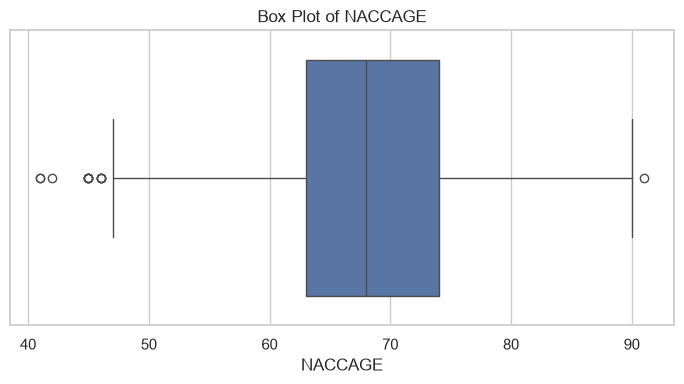

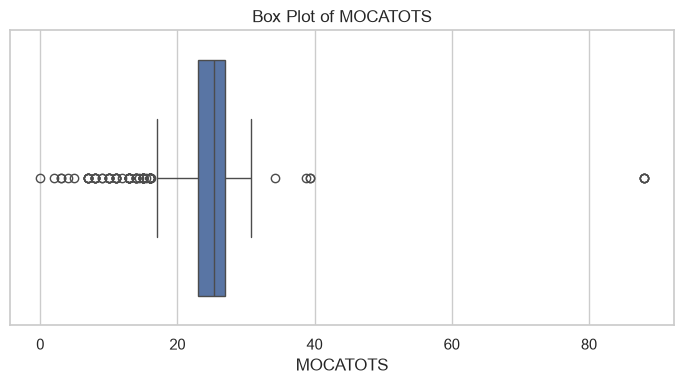

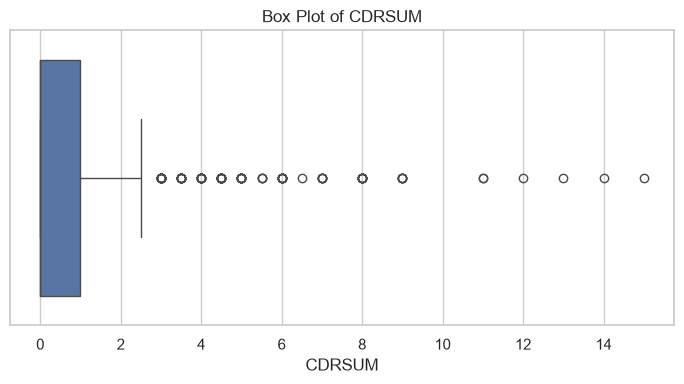

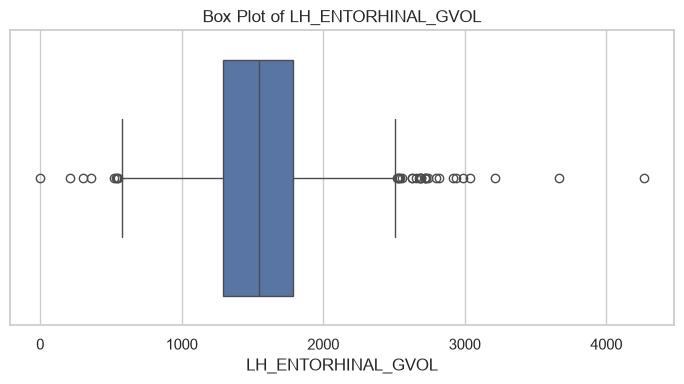

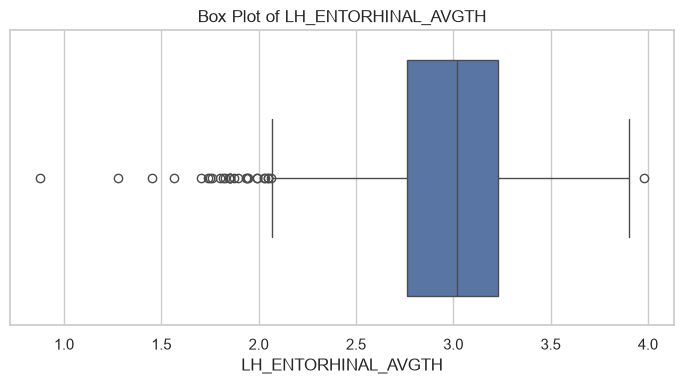

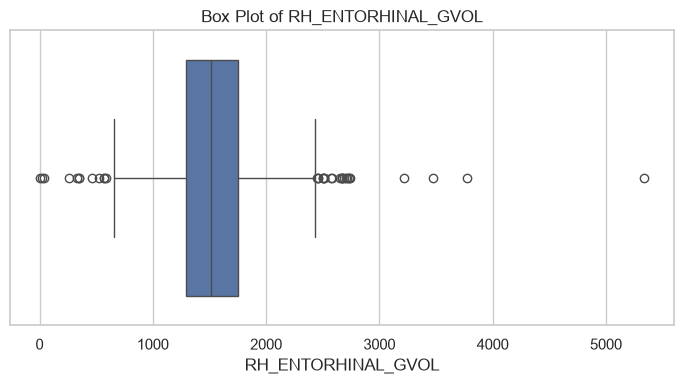

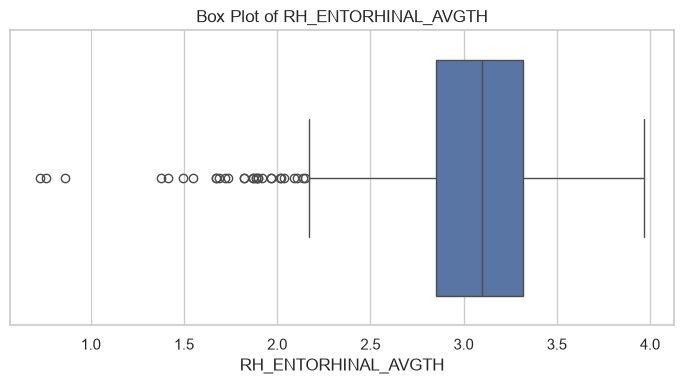

In [18]:

for var in numeric_variables:

    plt.figure(figsize=(7, 4))
    sns.boxplot(x=combined[var])

    plt.title(f"Box Plot of {var}")
    plt.xlabel(var)

    plt.tight_layout()
    plt.show()

مشاهده میشه که برای متغییر MOCATOTS  داده ها بین بازه ی  0 تا 40 قرار دارند ولی 4 تا  شرکت کننده عجیب دارای کد 88 اند در نتیجهه این را کدی برای میسینگ ولیو در نظر میگیریم. 

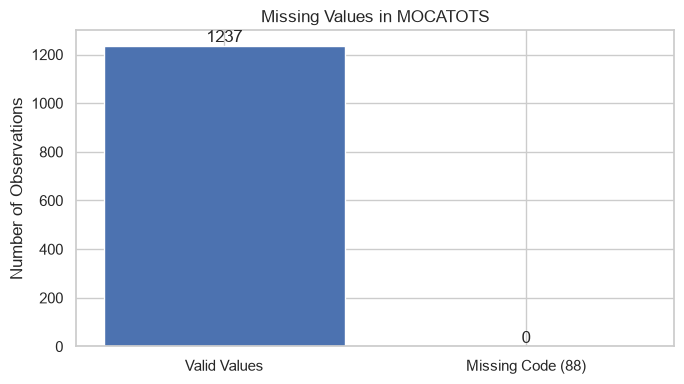

In [26]:


var = "MOCATOTS"

# شمارش مقادیر معتبر و کدهای 88
valid_count = (combined[var] != 88).sum()
missing_count = (combined[var] == 88).sum()

plt.figure(figsize=(7, 4))

plt.bar(
    ["Valid Values", "Missing Code (88)"],
    [valid_count, missing_count]
)

plt.title("Missing Values in MOCATOTS")
plt.ylabel("Number of Observations")

plt.text(0, valid_count, str(valid_count), ha="center", va="bottom")
plt.text(1, missing_count, str(missing_count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [27]:
# Replace the missing-value code with NaN
combined["MOCATOTS"] = combined["MOCATOTS"].replace(88, float("nan"))

# Remove rows with missing MOCATOTS values
combined1 = combined.copy()
combined1 = combined1.dropna(subset=["MOCATOTS"])

print("Original dataset shape:", combined.shape)
print("Cleaned dataset shape:", combined1.shape)
print("Remaining missing values:", combined1["MOCATOTS"].isna().sum())

Original dataset shape: (1237, 305)
Cleaned dataset shape: (1233, 305)
Remaining missing values: 0


تا اینجا سطر هایی که دارای میسینگ ولیو برای ماکتوتس بودن رو حذف  کردیم و با  دیتاست جدید پیش میرویم.

In [28]:
summary_results = []

for variable in numeric_variables:

    data = pd.to_numeric(combined1[variable], errors="coerce").dropna()

    mean_value = data.mean()
    median_value = data.median()

    summary_results.append({
        "Variable": variable,
        "Count": data.count(),
        "Mean": mean_value,
        "Median": median_value,
        "Std": data.std(),
        "Min": data.min(),
        "Max": data.max(),
        "Q1": data.quantile(0.25),
        "Q3": data.quantile(0.75),
        "IQR": data.quantile(0.75) - data.quantile(0.25),
        "Below Mean": (data < mean_value).sum(),
        "Equal Mean": (data == mean_value).sum(),
        "Above Mean": (data > mean_value).sum()
    })

summary_df = pd.DataFrame(summary_results)

display(summary_df.round(2))

,Variable,Count,Mean,Median,Std,Min,Max,Q1,Q3,IQR,Below Mean,Equal Mean,Above Mean
0,NACCAGE,1233,68.19,68.00,8.05,41.00,91.00,63.00,74.00,11.00,622,0,611
1,MOCATOTS,1233,24.44,25.40,4.49,0.00,39.40,23.00,27.00,4.00,466,0,767
2,CDRSUM,1233,0.81,0.00,1.68,0.00,15.00,0.00,1.00,1.00,900,0,333
3,LH_ENTORHINAL_GVOL,1233,"1,554.61","1,545.00",413.94,0.00,"4,265.00","1,295.00","1,785.00",490.00,633,0,600
4,LH_ENTORHINAL_AVGTH,1233,2.97,3.02,0.38,0.88,3.98,2.76,3.23,0.46,537,0,696
5,RH_ENTORHINAL_GVOL,1233,"1,526.11","1,513.00",405.32,6.00,"5,334.00","1,290.00","1,748.00",458.00,640,0,593
6,RH_ENTORHINAL_AVGTH,1233,3.06,3.10,0.40,0.73,3.97,2.86,3.32,0.47,549,0,684


نمودار های توزیع متغییر های اصلی و همچنین پراکندگی انها بعد از حذف میسینگ ولیو

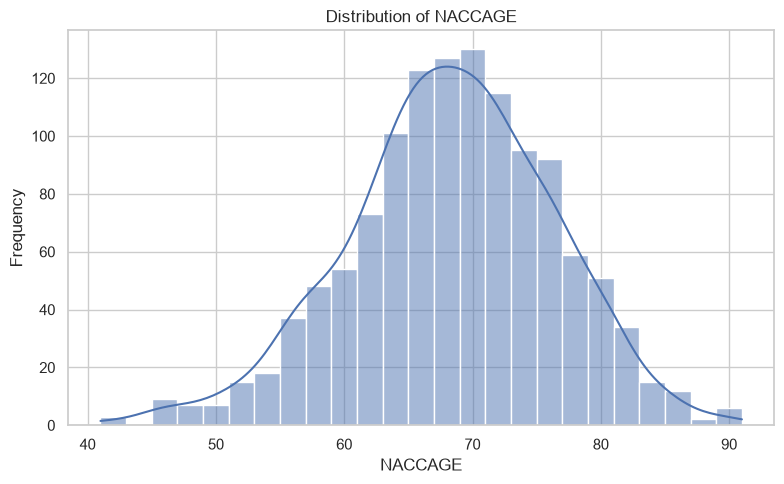

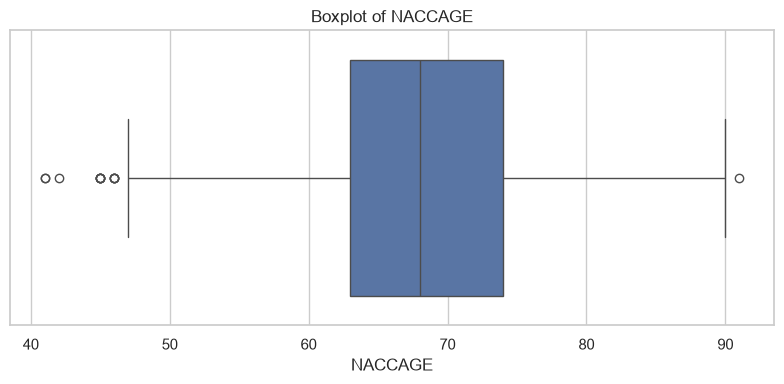

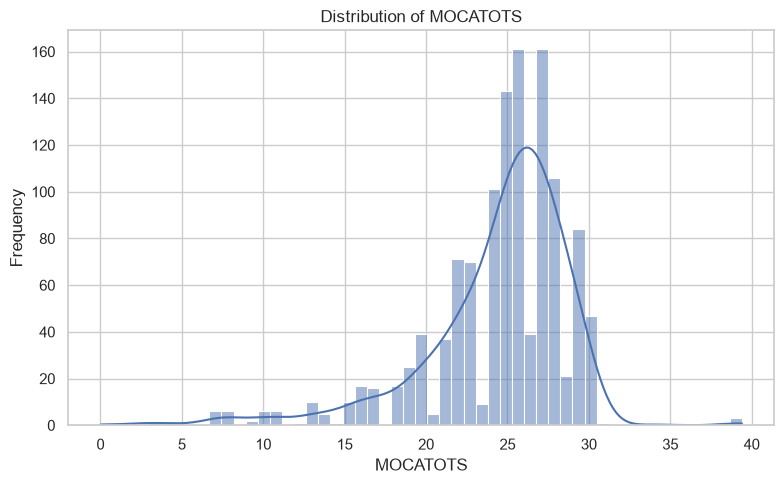

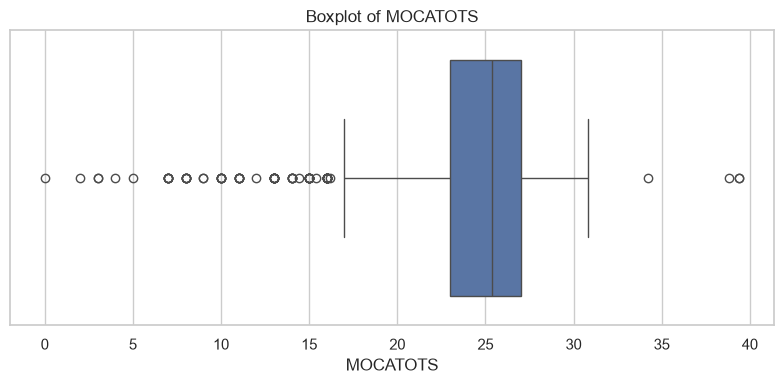

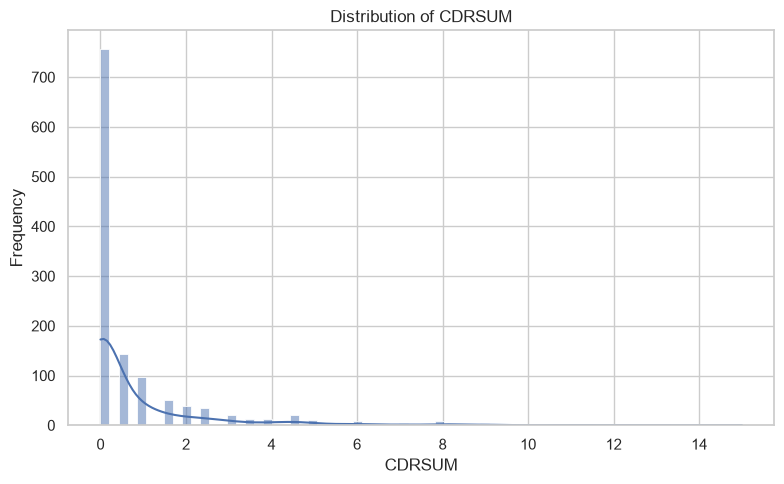

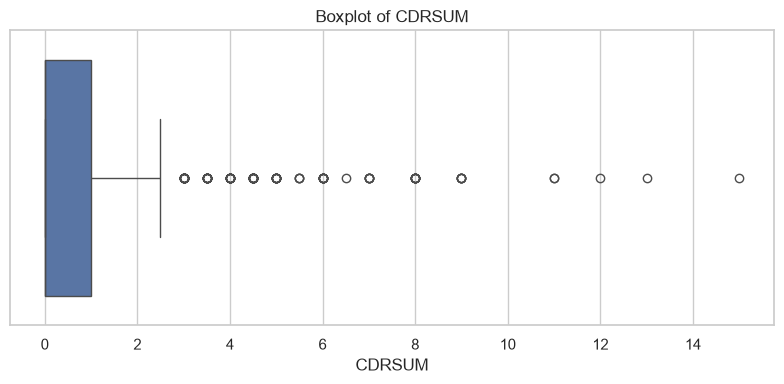

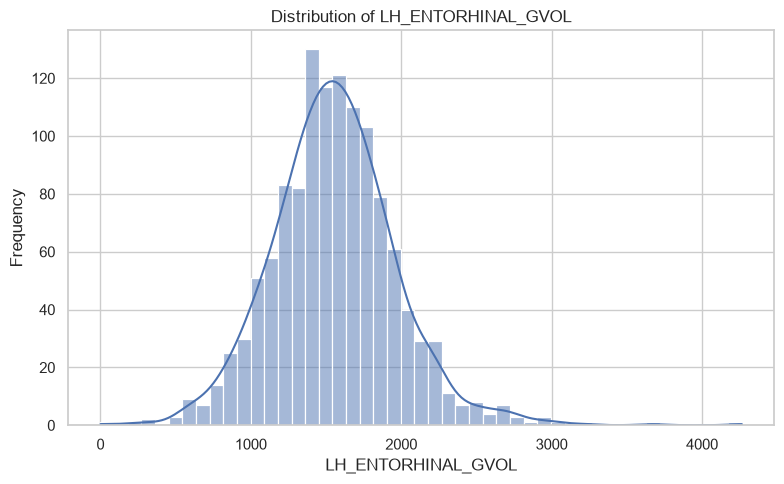

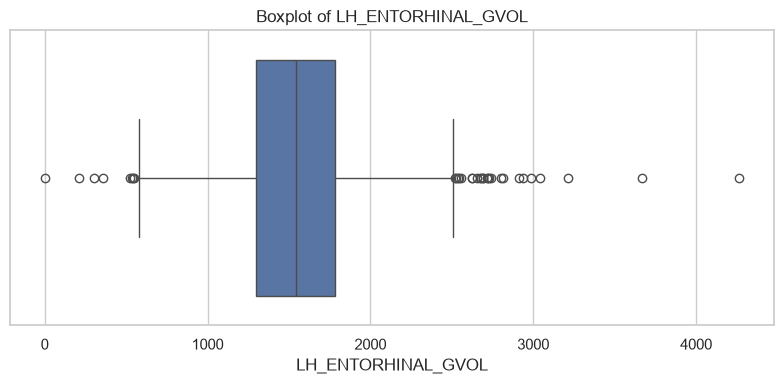

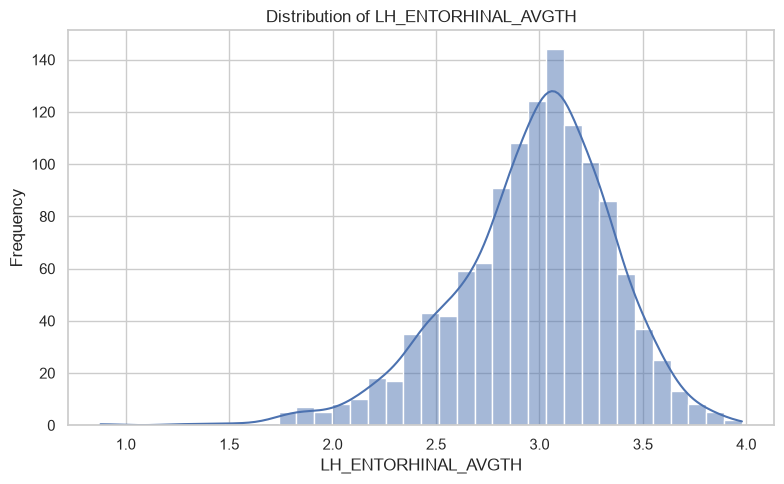

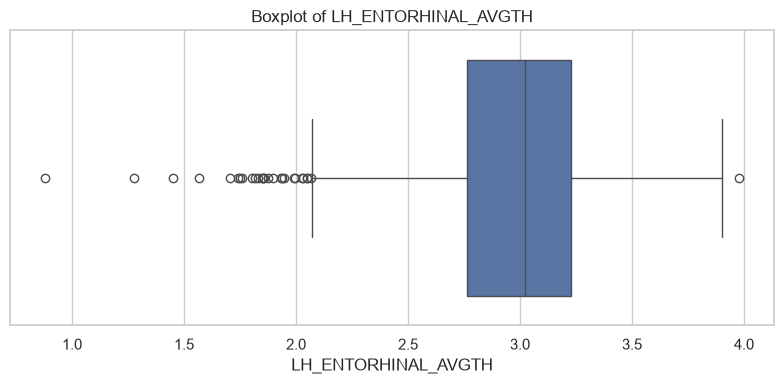

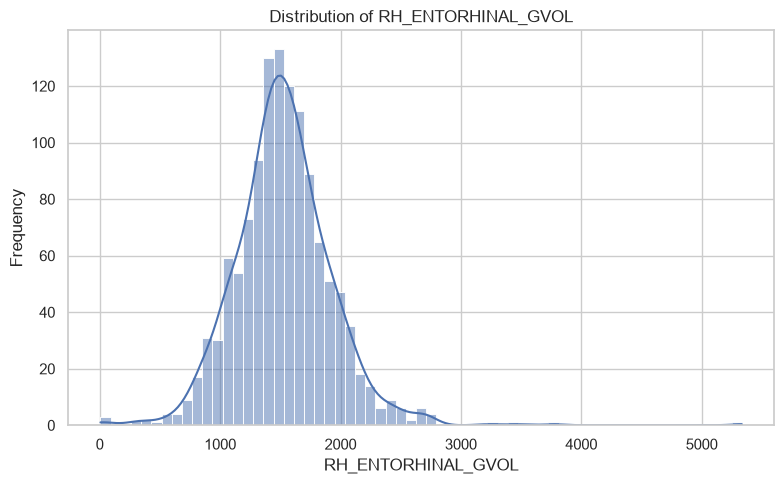

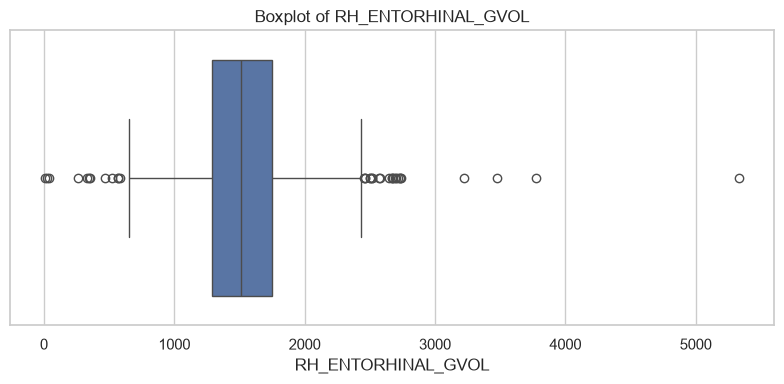

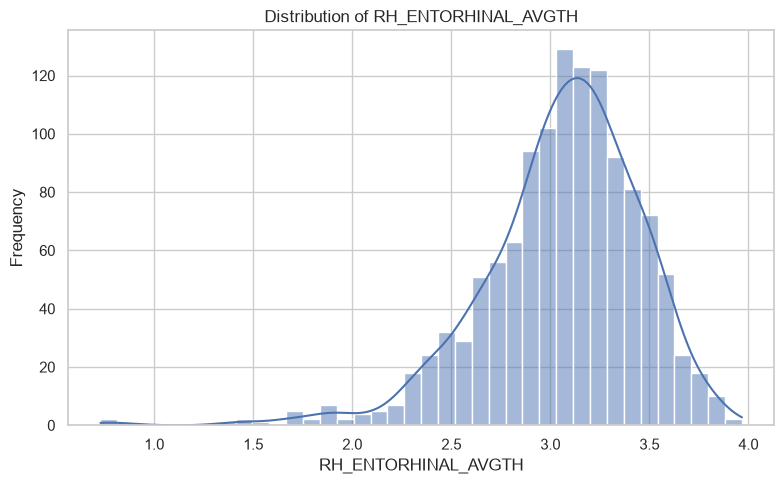

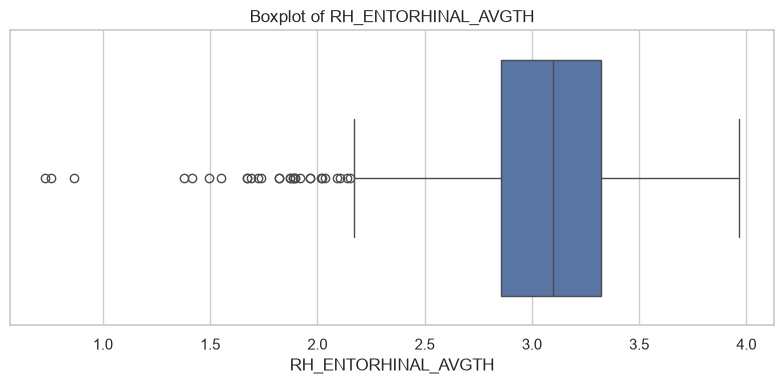

In [29]:


for variable in numeric_variables:

    data = pd.to_numeric(
        combined1[variable],
        errors="coerce"
    ).dropna()

    # Histogram
    plt.figure(figsize=(8, 5))

    sns.histplot(data, kde=True)

    plt.title(f"Distribution of {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    # Boxplot
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=data)

    plt.title(f"Boxplot of {variable}")
    plt.xlabel(variable)

    plt.tight_layout()
    plt.show()

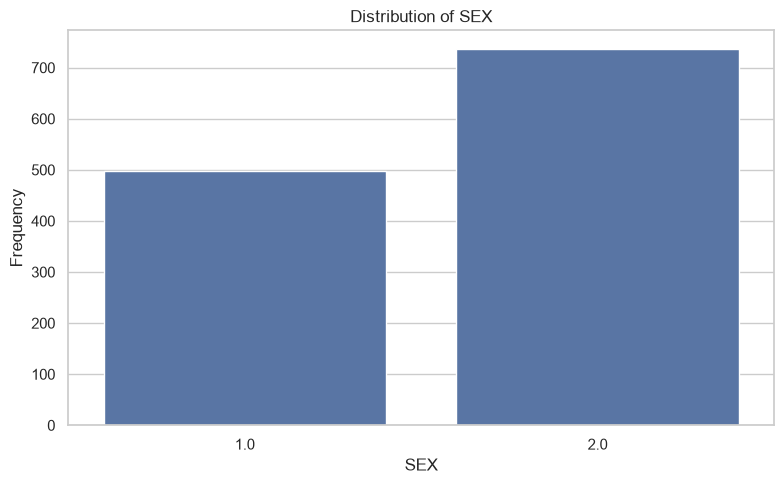

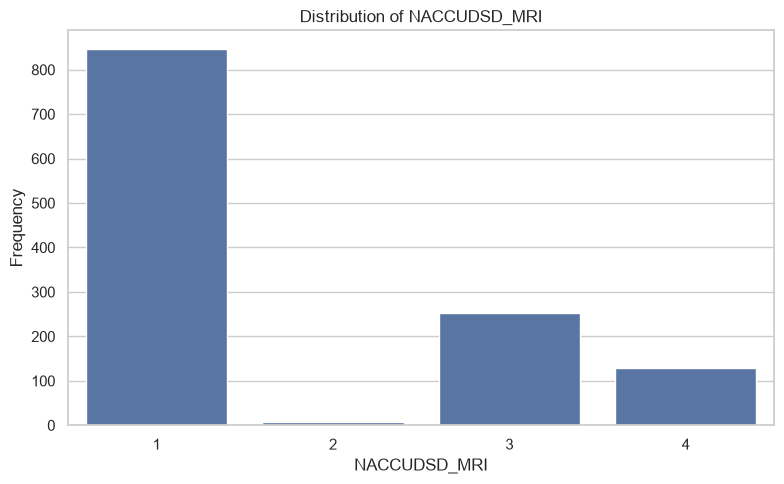

In [30]:
categorical_variables = [
    "SEX",
    "NACCUDSD_MRI"
]

for variable in categorical_variables:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=combined1,
        x=variable
    )

    plt.title(f"Distribution of {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

مقایسه های توصیفی

1. مقایسه ی سن و وضعیت شناختی

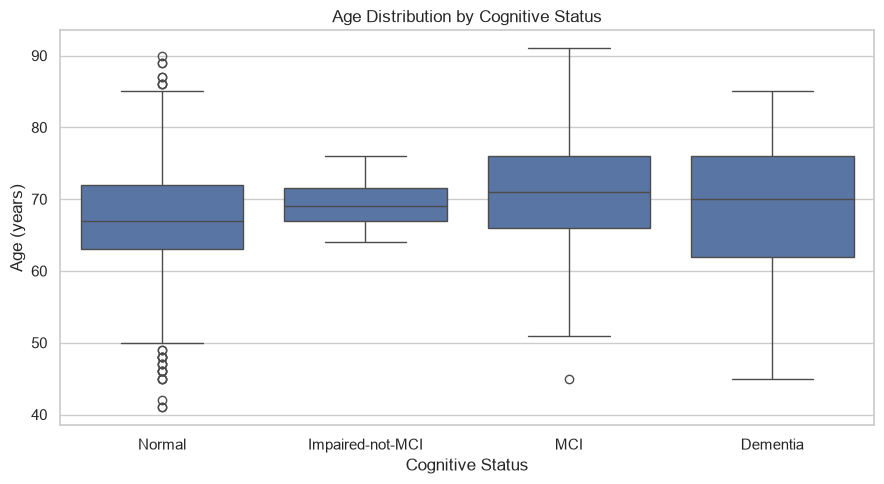

In [34]:
cognitive_labels = {
    1: "Normal",
    2: "Impaired-not-MCI",
    3: "MCI",
    4: "Dementia"
}

combined1["Cognitive_Group"] = pd.to_numeric(
    combined1["NACCUDSD_UDS"], errors="coerce"
).map(cognitive_labels)

group_order = ["Normal", "Impaired-not-MCI", "MCI", "Dementia"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=combined1,
    x="Cognitive_Group",
    y="NACCAGE",
    order=group_order
)

plt.title("Age Distribution by Cognitive Status")
plt.xlabel("Cognitive Status")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()

2. مقایسه ی ضخامت قشر انتوریال چپ

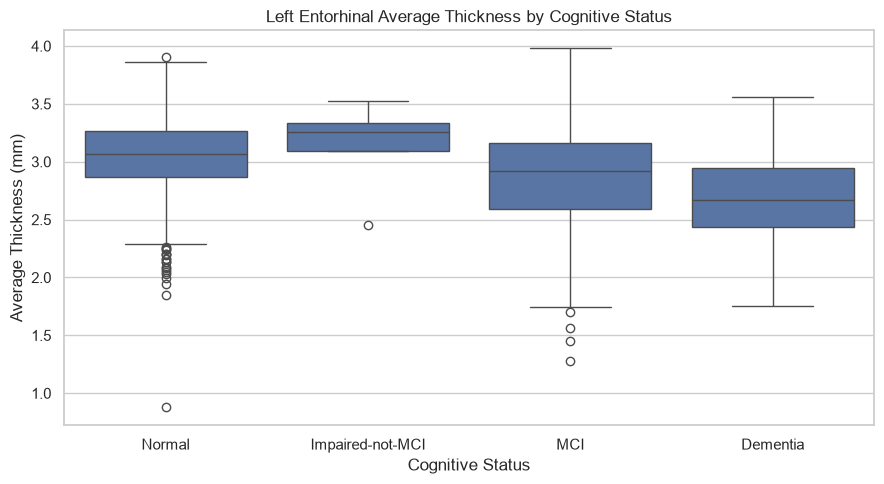

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=combined1,
    x="Cognitive_Group",
    y="LH_ENTORHINAL_AVGTH",
    order=group_order
)

plt.title("Left Entorhinal Average Thickness by Cognitive Status")
plt.xlabel("Cognitive Status")
plt.ylabel("Average Thickness (mm)")
plt.tight_layout()
plt.show()